# 02 Smoke test on the swarm days (2–3 November 2025 UTC)

Before the parameters are frozen and the whole period is processed, the pipeline is run on the two days that contain the swarm (2025 day-of-year 306–307).
The test passes when:

1. picks come from (nearly) every station that recorded;
2. all 24 KMA-listed events are found within 12 s of their KMA origin times;
3. the ML 1.9 event locates within about 1 km of its earlier hand-pick solution (35.5506° N, 127.2951° E, 14.40 km; Kim et al. 2011 model; this run uses Kim & Kim 1983), at 12–16 km depth;
4. the PhaseNet+ picks of the ML 1.9 agree with the hand picks (median absolute difference ≤ 0.1 s for P and ≤ 0.2 s for S).

The notebook also gives the evidence for decision **D1** (station elevations of 0 m, the Haenam convention, versus real elevations).

In [1]:
import os, sys, glob, subprocess, shutil, tempfile
import numpy as np, pandas as pd
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
os.environ['PATH'] = '/home/msseo/works/72.2025_Imsil_swarm/_external/bin:' + os.environ['PATH']   # hyp1.40 wrapper
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'; PROJECT = os.path.dirname(DL)
sys.path.insert(0, f'{DL}/pipeline')
import config, core, sumio, plotstyle  # noqa: F401
import matplotlib.pyplot as plt, pygmt
from obspy import read
pd.set_option('display.width', 200)
MODEL, YEAR, DAYS = 'phasenet_plus_smoke', 2025, (306, 307)   # smoke outputs moved aside before the frozen run (models/phasenet_plus_smoke)
LAT0, LON0 = config.IMSIL_EPICENTER
def dist_km(la, lo, la0=LAT0, lo0=LON0):
    return np.hypot((np.asarray(lo) - lo0) * 111.19 * np.cos(np.radians(la0)), (np.asarray(la) - la0) * 111.19)
picks = pd.concat([pd.read_csv(f'{config.picks_dir(MODEL, YEAR)}/picks_{YEAR}.{d:03d}.csv') for d in DAYS], ignore_index=True)
picks['t'] = pd.to_datetime(picks.peak_time).dt.tz_localize(None)
ev = pd.read_csv(config.pyocto_events(MODEL, YEAR))
sumf = os.path.join(config.velmodel_dir(MODEL, 'kim1983'), f'{config.REGION_NAME}{YEAR}.sum')
loc = sumio.read_sum(sumf)
cat = pd.read_csv(f'{DL}/models/phasenet_plus_smoke/imsil_dl_catalog_smoke.csv', parse_dates=['time'])
kma = pd.read_csv(f'{DL}/catalogs/imsil_kma24.csv', dtype={'event_id': str}, parse_dates=['origin_time_UTC'])
print(f'picks {len(picks)} ({(picks.phase == "P").sum()} P, {(picks.phase == "S").sum()} S) at {picks.station.nunique()} stations; '
      f'PyOcto events {len(ev)}; located {len(loc)}; catalog rows {len(cat)}')

picks 17079 (7299 P, 9780 S) at 54 stations; PyOcto events 63; located 63; catalog rows 63


## 1. Picks per station

In [2]:
st = pd.read_csv(config.STATIONS_CSV); st['dist_km'] = dist_km(st.Latitude, st.Longitude)
pc = picks.assign(code=picks.station.str.split('.').str[1]).groupby(['code', 'phase']).size().unstack(fill_value=0)
tab = st.set_index('Code')[['dist_km']].join(pc).fillna(0).sort_values('dist_km')
display(tab.astype({'P': int, 'S': int}).round(1).T)
n_sta_picked = int((tab[['P', 'S']].sum(axis=1) > 0).sum())
print(f'stations with picks: {n_sta_picked} of {len(st)}; without: {", ".join(tab.index[(tab[["P", "S"]].sum(axis=1) == 0)]) or "none"}')

Code,IMSB,NAWB,SIDA,MALA,JASA,SUCA,JEU2,TAIA,CHOA,GKSA,...,BUYB,TEJ2,EURB,GICA,CPR2,SIJA,CJDB,YESA,OKCB,NAHA
dist_km,6.9,17.0,19.5,22.1,23.6,24.2,33.7,34.7,36.1,36.2,...,87.1,91.6,93.3,93.8,96.5,96.9,98.1,98.8,99.3,99.6
P,49.0,45.0,216.0,215.0,837.0,387.0,72.0,76.0,23.0,361.0,...,11.0,107.0,4.0,162.0,87.0,48.0,154.0,47.0,11.0,209.0
S,36.0,38.0,223.0,295.0,1182.0,487.0,107.0,153.0,30.0,456.0,...,12.0,150.0,2.0,202.0,112.0,53.0,214.0,58.0,5.0,379.0


stations with picks: 54 of 54; without: none


## 2. Recovery of the 24 KMA-listed events

In [3]:
rows = []
for r in kma.itertuples():
    d = (cat.time - r.origin_time_UTC).dt.total_seconds().abs()
    i = d.idxmin() if len(d) else None
    ok = i is not None and d[i] <= 12
    rows.append(dict(kma_id=r.event_id, kma_time=r.origin_time_UTC, kma_ml=r.ML, found=ok, dt_s=round(float(d[i]), 2) if ok else np.nan,
                     tier=cat.tier[i] if ok else '', lat=cat.lat[i] if ok else np.nan, lon=cat.lon[i] if ok else np.nan,
                     depth_km=cat.depth[i] if ok else np.nan, num=cat.num[i] if ok else np.nan, rms=cat.rms[i] if ok else np.nan))
rec = pd.DataFrame(rows); rec['epi_km_from_imsil'] = dist_km(rec.lat, rec.lon).round(2)
display(rec)
n_found = int(rec.found.sum())
print(f'KMA events found within 12 s: {n_found} of {len(rec)}; tiers: {rec.tier.value_counts().to_dict()}')

,kma_id,kma_time,kma_ml,found,dt_s,tier,lat,lon,depth_km,num,rms,epi_km_from_imsil
0,20251102200539,2025-11-02 20:05:39,1.4,True,0.26,A,35.5499,127.2936,15.14,28,0.20,0.16
1,20251102200625,2025-11-02 20:06:25,1.4,True,0.16,A,35.5486,127.2982,14.19,14,0.17,0.36
2,20251102201044,2025-11-02 20:10:44,1.3,True,0.18,A,35.5503,127.2960,14.59,22,0.19,0.09
3,20251102202339,2025-11-02 20:23:39,1.5,True,0.60,A,35.5522,127.2932,14.97,35,0.20,0.25
4,20251102202412,2025-11-02 20:24:12,1.5,True,0.18,A,35.5509,127.2948,14.56,51,0.22,0.04
5,20251102202939,2025-11-02 20:29:39,1.0,True,0.88,A,35.5528,127.2939,14.60,33,0.19,0.27
6,20251102203236,2025-11-02 20:32:36,1.7,True,0.41,A,35.5490,127.2980,14.54,22,0.17,0.32
7,20251102203649,2025-11-02 20:36:49,1.3,True,0.79,A,35.5508,127.2948,14.80,35,0.18,0.04
8,20251102203835,2025-11-02 20:38:35,1.9,True,0.23,A,35.5502,127.2962,14.62,98,0.19,0.11
9,20251102204002,2025-11-02 20:40:02,1.3,True,0.35,A,35.5512,127.2920,14.50,35,0.18,0.29


KMA events found within 12 s: 24 of 24; tiers: {'A': 24}


## 3. The ML 1.9 event against its hand-pick solution

In [4]:
m = rec[rec.kma_ml == rec.kma_ml.max()].iloc[0]
d_epi = float(dist_km(m.lat, m.lon, 35.5506, 127.2951))
print(f'ML 1.9 ({m.kma_time}): DL {m.lat:.4f} N {m.lon:.4f} E {m.depth_km:.2f} km (tier {m.tier}, {m.num:.0f} phases, RMS {m.rms:.2f} s)')
print(f'  vs hand picks (kim2011) 35.5506 N 127.2951 E 14.40 km: epicentral offset {d_epi:.2f} km, depth difference {m.depth_km - 14.40:+.2f} km')
ml19_ok = d_epi <= 1.0 and 12 <= m.depth_km <= 16

ML 1.9 (2025-11-02 20:38:35): DL 35.5502 N 127.2962 E 14.62 km (tier A, 98 phases, RMS 0.19 s)
  vs hand picks (kim2011) 35.5506 N 127.2951 E 14.40 km: epicentral offset 0.11 km, depth difference +0.22 km


## 4. PhaseNet+ picks against the hand picks of the ML 1.9

The hand picks are stored in the event SAC files (`waveforms_100km/20251102203835`, SAC header `a` = P, `t0` = S).

,n,median,median_abs,p90_abs
phase,,,,
P,46,-0.000,0.010,0.042
S,43,0.029,0.032,0.064


hand picks: 95 (48 P, 47 S); matched within 1 s: 89


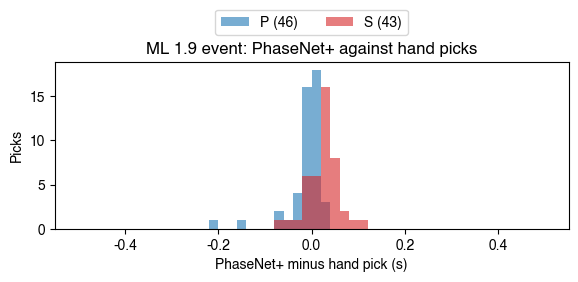

In [5]:
hp = []
for f in glob.glob(f'{PROJECT}/waveforms_100km/20251102203835/*.sac'):
    tr = read(f, headonly=True)[0]; h = tr.stats.sac; t0 = tr.stats.starttime - h.b
    for ph, key in (('P', 'a'), ('S', 't0')):
        if key in h and h[key] not in (None, -12345.0):
            hp.append(dict(code=tr.stats.station, phase=ph, t_hand=(t0 + h[key]).datetime))
hp = pd.DataFrame(hp).drop_duplicates(['code', 'phase'])
win = picks[(picks.t > pd.Timestamp('2025-11-02 20:38:20')) & (picks.t < pd.Timestamp('2025-11-02 20:39:30'))].copy()
win['code'] = win.station.str.split('.').str[1]
cmp = []
for r in hp.itertuples():
    c = win[(win.code == r.code) & (win.phase == r.phase)]
    if len(c):
        dt = (c.t - r.t_hand).dt.total_seconds(); j = dt.abs().idxmin()
        if abs(dt[j]) <= 1.0:
            cmp.append(dict(code=r.code, phase=r.phase, dt_s=dt[j], prob=c.probability[j]))
cmp = pd.DataFrame(cmp)
summ = cmp.groupby('phase').dt_s.agg(n='size', median='median', median_abs=lambda x: x.abs().median(), p90_abs=lambda x: x.abs().quantile(.9)).round(3)
display(summ)
print(f'hand picks: {len(hp)} ({(hp.phase == "P").sum()} P, {(hp.phase == "S").sum()} S); matched within 1 s: {len(cmp)}')
fig, ax = plt.subplots(figsize=(6, 3))
for ph, col in (('P', 'tab:blue'), ('S', 'tab:red')):
    ax.hist(cmp[cmp.phase == ph].dt_s, bins=np.arange(-0.5, 0.51, 0.02), alpha=0.6, color=col, label=f'{ph} ({(cmp.phase == ph).sum()})')
ax.set_xlabel('PhaseNet+ minus hand pick (s)'); ax.set_ylabel('Picks'); ax.set_title('ML 1.9 event: PhaseNet+ against hand picks')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.12), ncol=2, frameon=True); plt.tight_layout(); plt.show()
pick_ok = (summ.loc['P', 'median_abs'] <= 0.1 if 'P' in summ.index else False) and (summ.loc['S', 'median_abs'] <= 0.2 if 'S' in summ.index else False)

## 5. Located events on the swarm days

plot [WARNING]: Cannot use auto-legend -l for variable symbol color. Option -l ignored.


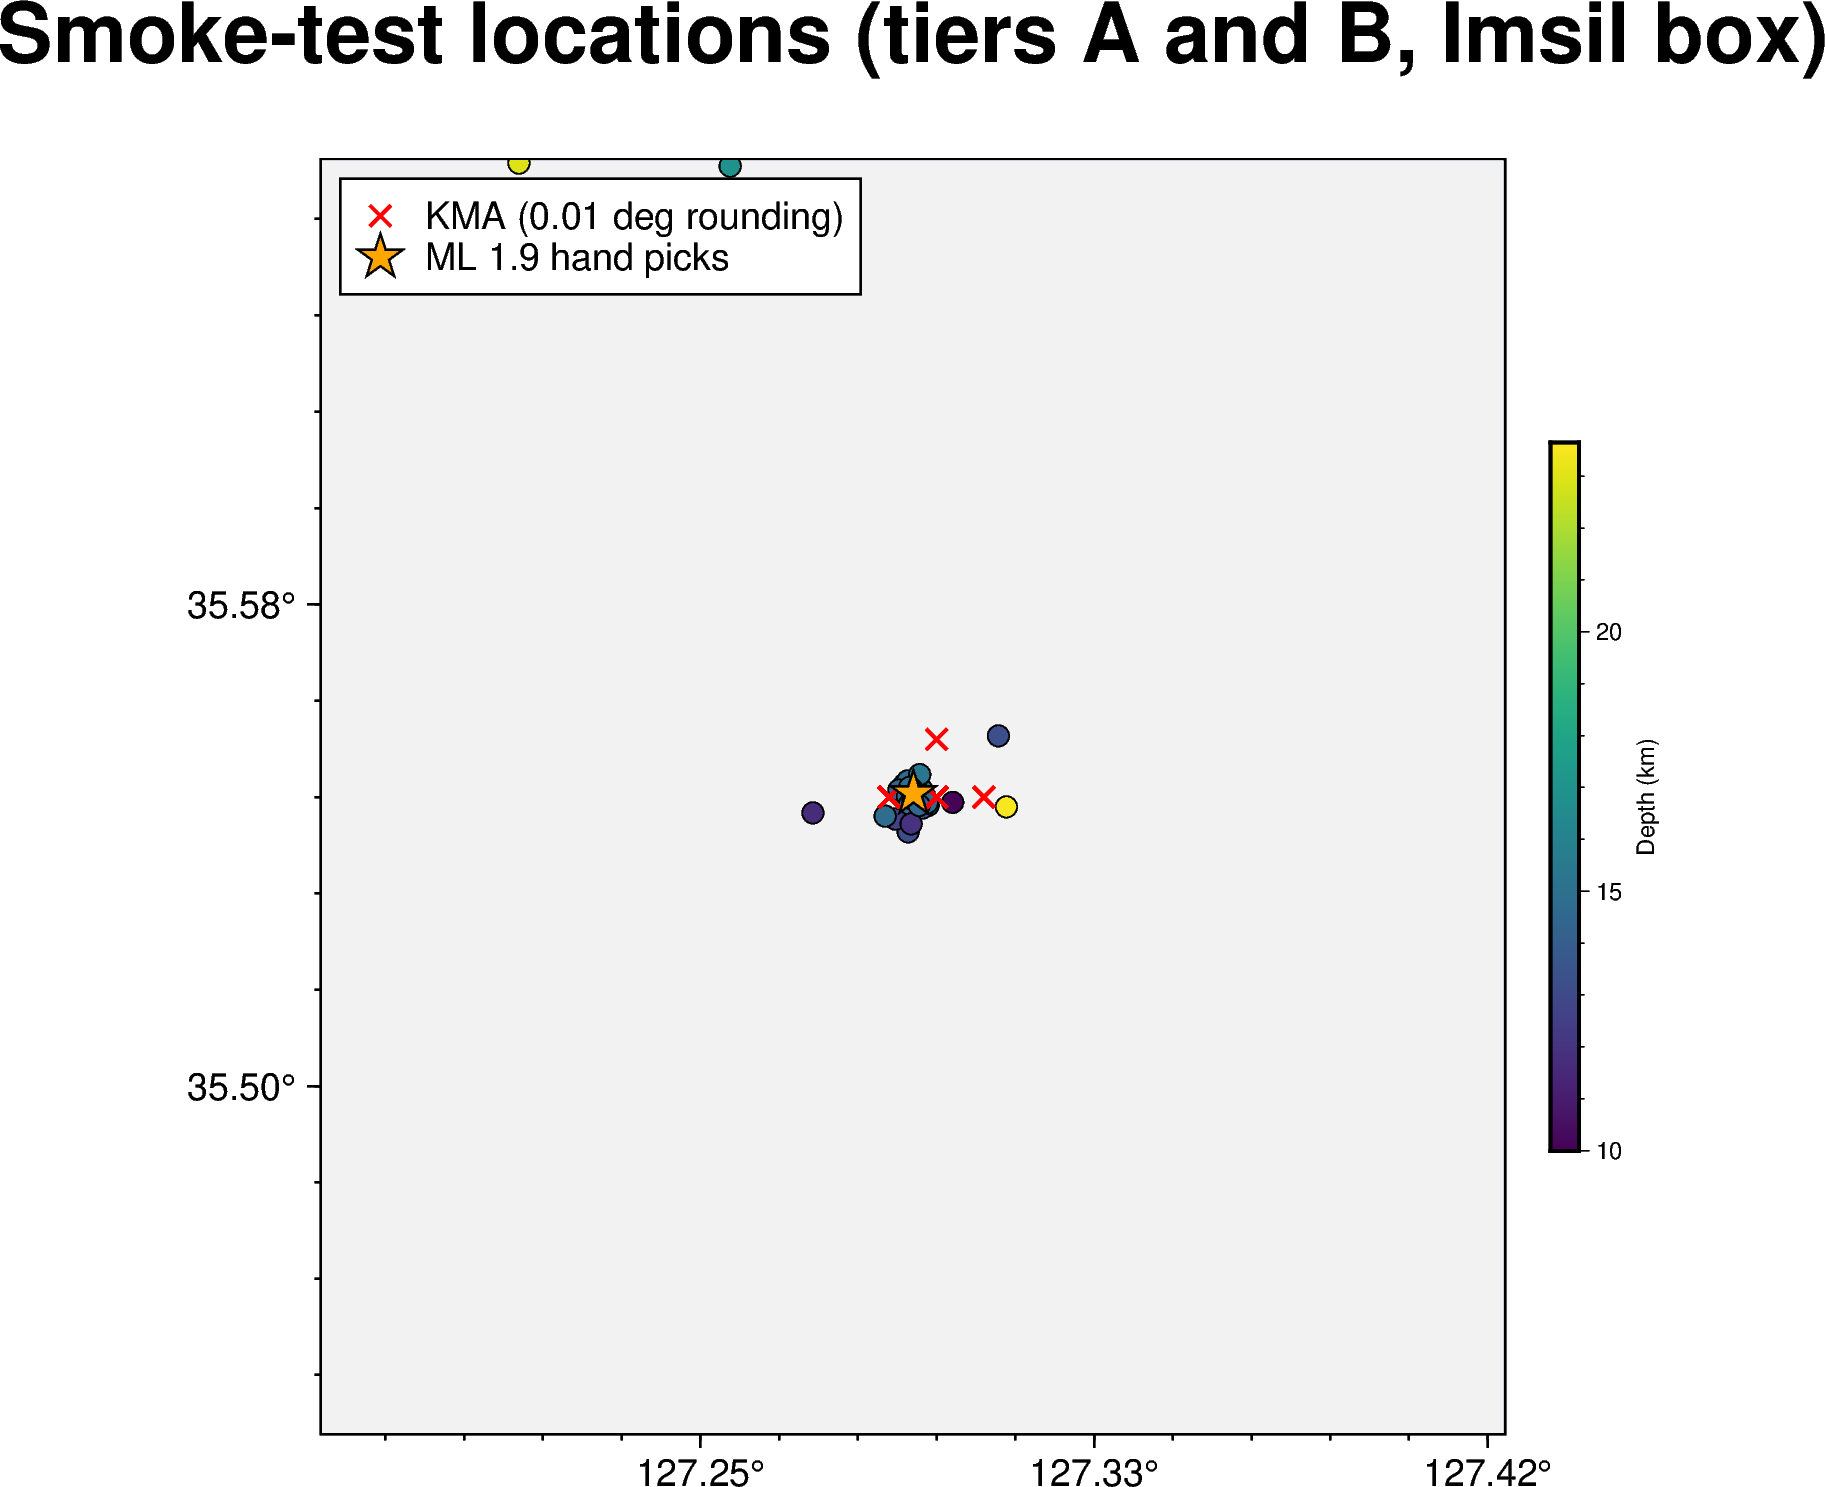

Imsil box, 2 Nov: this run 35 located (33 A/B); earlier PhaseNO+PyOcto run (11 stations, prob >= 0.5): 33 events


In [6]:
box = cat[cat.in_imsil_box & cat.tier.isin(['A', 'B'])].copy()
fig = pygmt.Figure()
pygmt.config(FORMAT_GEO_MAP='ddd.xx', MAP_FRAME_TYPE='plain', FONT_ANNOT_PRIMARY='9p', FONT_LABEL='9p')
b = config.IMSIL_BOX
fig.basemap(region=[b[2], b[3], b[0], b[1]], projection='M10c', frame=['af', '+tSmoke-test locations (tiers A and B, Imsil box)'])
fig.coast(land='gray95', water='lightblue')
if len(box):
    pygmt.makecpt(cmap='viridis', series=[box.depth.min() - 0.1, box.depth.max() + 0.1])
    fig.plot(x=box.lon, y=box.lat, style='c0.18c', fill=box.depth, cmap=True, pen='0.3p,black', label=f'DL A/B ({len(box)})')
    fig.colorbar(frame=['af', 'x+lDepth (km)'], position='JMR+o0.4c/0c+w6c')
fig.plot(x=kma.longitude, y=kma.latitude, style='x0.25c', pen='0.8p,red', label='KMA (0.01 deg rounding)')
fig.plot(x=[127.2951], y=[35.5506], style='a0.4c', fill='orange', pen='0.4p,black', label='ML 1.9 hand picks')
fig.legend(position='JTL+jTL+o0.15c', box='+gwhite+p0.5p')
fig.show()
prev = pd.read_csv(f'{PROJECT}/4.PyOcto/251102/pyocto_kim1983_prob0.5.csv', parse_dates=['time'])
prev_box = prev[(prev.latitude.between(b[0], b[1])) & (prev.longitude.between(b[2], b[3]))]
day = cat[(cat.time >= '2025-11-02') & (cat.time < '2025-11-03') & cat.in_imsil_box]
print(f'Imsil box, 2 Nov: this run {len(day)} located ({day.tier.isin(["A", "B"]).sum()} A/B); earlier PhaseNO+PyOcto run (11 stations, prob >= 0.5): {len(prev_box)} events')

## 6. Decision D1: station elevations

The Haenam station table puts every KS station at 0 m, and so does the default here.
The same phase file is located again in a scratch folder, with the real elevations of `station_table/kskg_used_stations_100km.csv` (42–698 m), and the locations are compared.
Only the HYPOINVERSE step is repeated; PyOcto, which also reads elevations, is not.

In [7]:
td = tempfile.mkdtemp(prefix='imsil_d1_')
shutil.copytree(config.hyp_dir(MODEL), f'{td}/HypoInv')
real = pd.read_csv(f'{DL}/station_table/kskg_used_stations_100km.csv').set_index('Code').Elevation
sta_file = f'{td}/HypoInv/STA/{config.REGION_NAME}{YEAR}_hyp.sta'
lines = open(sta_file).read().splitlines()
with open(sta_file, 'w') as f:
    for l in lines:
        f.write(l[:38] + f'{real.get(l[:5].strip(), 0.0):4.0f}' + l[42:] + '\n')
region = f'{config.REGION_NAME}{YEAR}'
control = (core.HYP_TEMPLATE.replace('__REGION__', region).replace('__MODEL__', 'kim1983')
           .replace('__DIS__', config.HYP_DIS).replace('__ZTR__', config.HYP_ZTR))
for ext in ('sum', 'prt', 'arc'):
    p = f'{td}/HypoInv/kim1983/{region}.{ext}'
    if os.path.exists(p): os.remove(p)
subprocess.run(['hyp1.40'], input=control, text=True, cwd=f'{td}/HypoInv', capture_output=True)
alt = sumio.read_sum(f'{td}/HypoInv/kim1983/{region}.sum')
a0 = loc.reset_index(drop=True); a1 = alt.reset_index(drop=True)
assert len(a0) == len(a1), (len(a0), len(a1))
dd = pd.DataFrame(dict(time=a0.time, epi_shift_m=1000 * dist_km(a1.lat, a1.lon, a0.lat.values, a0.lon.values),
                       depth_shift_m=1000 * (a1.depth - a0.depth), dt_origin_s=(a1.time - a0.time).dt.total_seconds()))
inb = (a0.lat.between(config.IMSIL_BOX[0], config.IMSIL_BOX[1]) & a0.lon.between(config.IMSIL_BOX[2], config.IMSIL_BOX[3])).values
d1 = dd[inb].describe().loc[['count', 'mean', '50%', 'max']].round(2)
display(d1)
qc0 = len(sumio.apply_qc(a0[inb], config.IMSIL_QC)); qc1 = len(sumio.apply_qc(a1[inb], config.IMSIL_QC))
same_sum = open(sumf).read() == open(f'{td}/HypoInv/kim1983/{region}.sum').read()
print('HYPOINVERSE summary files identical:', same_sum, '-> with the CRH (layered) models hyp1.40 ignores station elevations' if same_sum else '')
print(f'in-box events passing the relocation QC gate: elevation 0 m -> {qc0}; real elevations -> {qc1}')

,time,epi_shift_m,depth_shift_m,dt_origin_s
count,40,40.0,40.0,40.0
mean,2025-11-02 21:35:09.197250048,0.0,0.0,0.0
50%,2025-11-02 21:05:38.920000,0.0,0.0,0.0
max,2025-11-03 02:49:27.950000,0.0,0.0,0.0


HYPOINVERSE summary files identical: True -> with the CRH (layered) models hyp1.40 ignores station elevations
in-box events passing the relocation QC gate: elevation 0 m -> 34; real elevations -> 34


## Comprehensive summary

In [8]:
p_med = summ.loc['P', 'median_abs'] if 'P' in summ.index else np.nan; s_med = summ.loc['S', 'median_abs'] if 'S' in summ.index else np.nan
summary = pd.DataFrame([
    ('Stations with picks', f'{n_sta_picked} of {len(st)}', n_sta_picked >= len(st) - 4),
    ('KMA events found within 12 s', f'{n_found} of {len(rec)}', n_found == len(rec)),
    ('ML 1.9 epicentral offset from hand picks (km)', round(d_epi, 2), d_epi <= 1.0),
    ('ML 1.9 depth (km)', round(float(m.depth_km), 2), 12 <= m.depth_km <= 16),
    ('Median |PhaseNet+ - hand| P (s)', p_med, bool(p_med <= 0.1)),
    ('Median |PhaseNet+ - hand| S (s)', s_med, bool(s_med <= 0.2)),
    ('D1: median epicentral shift with real elevations (m, in box)', round(float(dd[inb].epi_shift_m.median()), 1), None),
    ('D1: median depth shift with real elevations (m, in box)', round(float(dd[inb].depth_shift_m.median()), 1), None),
], columns=['check', 'value', 'pass'])
display(summary)
smoke_pass = bool(summary['pass'].dropna().astype(bool).all())
print('SMOKE TEST:', 'PASS - the parameters can be frozen and the whole period run' if smoke_pass else 'NOT PASSED - see the rows marked False')
print('Take-home points')
print(f'  - PhaseNet+ with the Haenam weights and settings finds {n_found} of the 24 KMA events on the swarm days.')
print(f'  - The ML 1.9 locates {d_epi:.2f} km from its hand-pick epicentre, at {m.depth_km:.1f} km depth (Kim & Kim 1983 model).')
print(f'  - D1: real station elevations move the in-box events by a median {dd[inb].epi_shift_m.median():.0f} m horizontally and {dd[inb].depth_shift_m.median():.0f} m in depth' + ('; the HYPOINVERSE outputs are byte-identical (CRH models ignore elevation), so the Haenam convention of 0 m is kept.' if same_sum else '.'))
print('The smoke outputs live in models/phasenet_plus_smoke (moved aside before the frozen run, as planned). Next: ./run_imsil.sh years 2025-2026 run (notebook 03).')

,check,value,pass
0,Stations with picks,54 of 54,True
1,KMA events found within 12 s,24 of 24,True
2,ML 1.9 epicentral offset from hand picks (km),0.11,True
3,ML 1.9 depth (km),14.62,True
4,Median |PhaseNet+ - hand| P (s),0.01,True
5,Median |PhaseNet+ - hand| S (s),0.032,True
6,D1: median epicentral shift with real elevatio...,0.0,None
7,D1: median depth shift with real elevations (m...,0.0,None


SMOKE TEST: PASS - the parameters can be frozen and the whole period run
Take-home points
  - PhaseNet+ with the Haenam weights and settings finds 24 of the 24 KMA events on the swarm days.
  - The ML 1.9 locates 0.11 km from its hand-pick epicentre, at 14.6 km depth (Kim & Kim 1983 model).
  - D1: real station elevations move the in-box events by a median 0 m horizontally and 0 m in depth; the HYPOINVERSE outputs are byte-identical (CRH models ignore elevation), so the Haenam convention of 0 m is kept.
The smoke outputs live in models/phasenet_plus_smoke (moved aside before the frozen run, as planned). Next: ./run_imsil.sh years 2025-2026 run (notebook 03).
